In [1]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

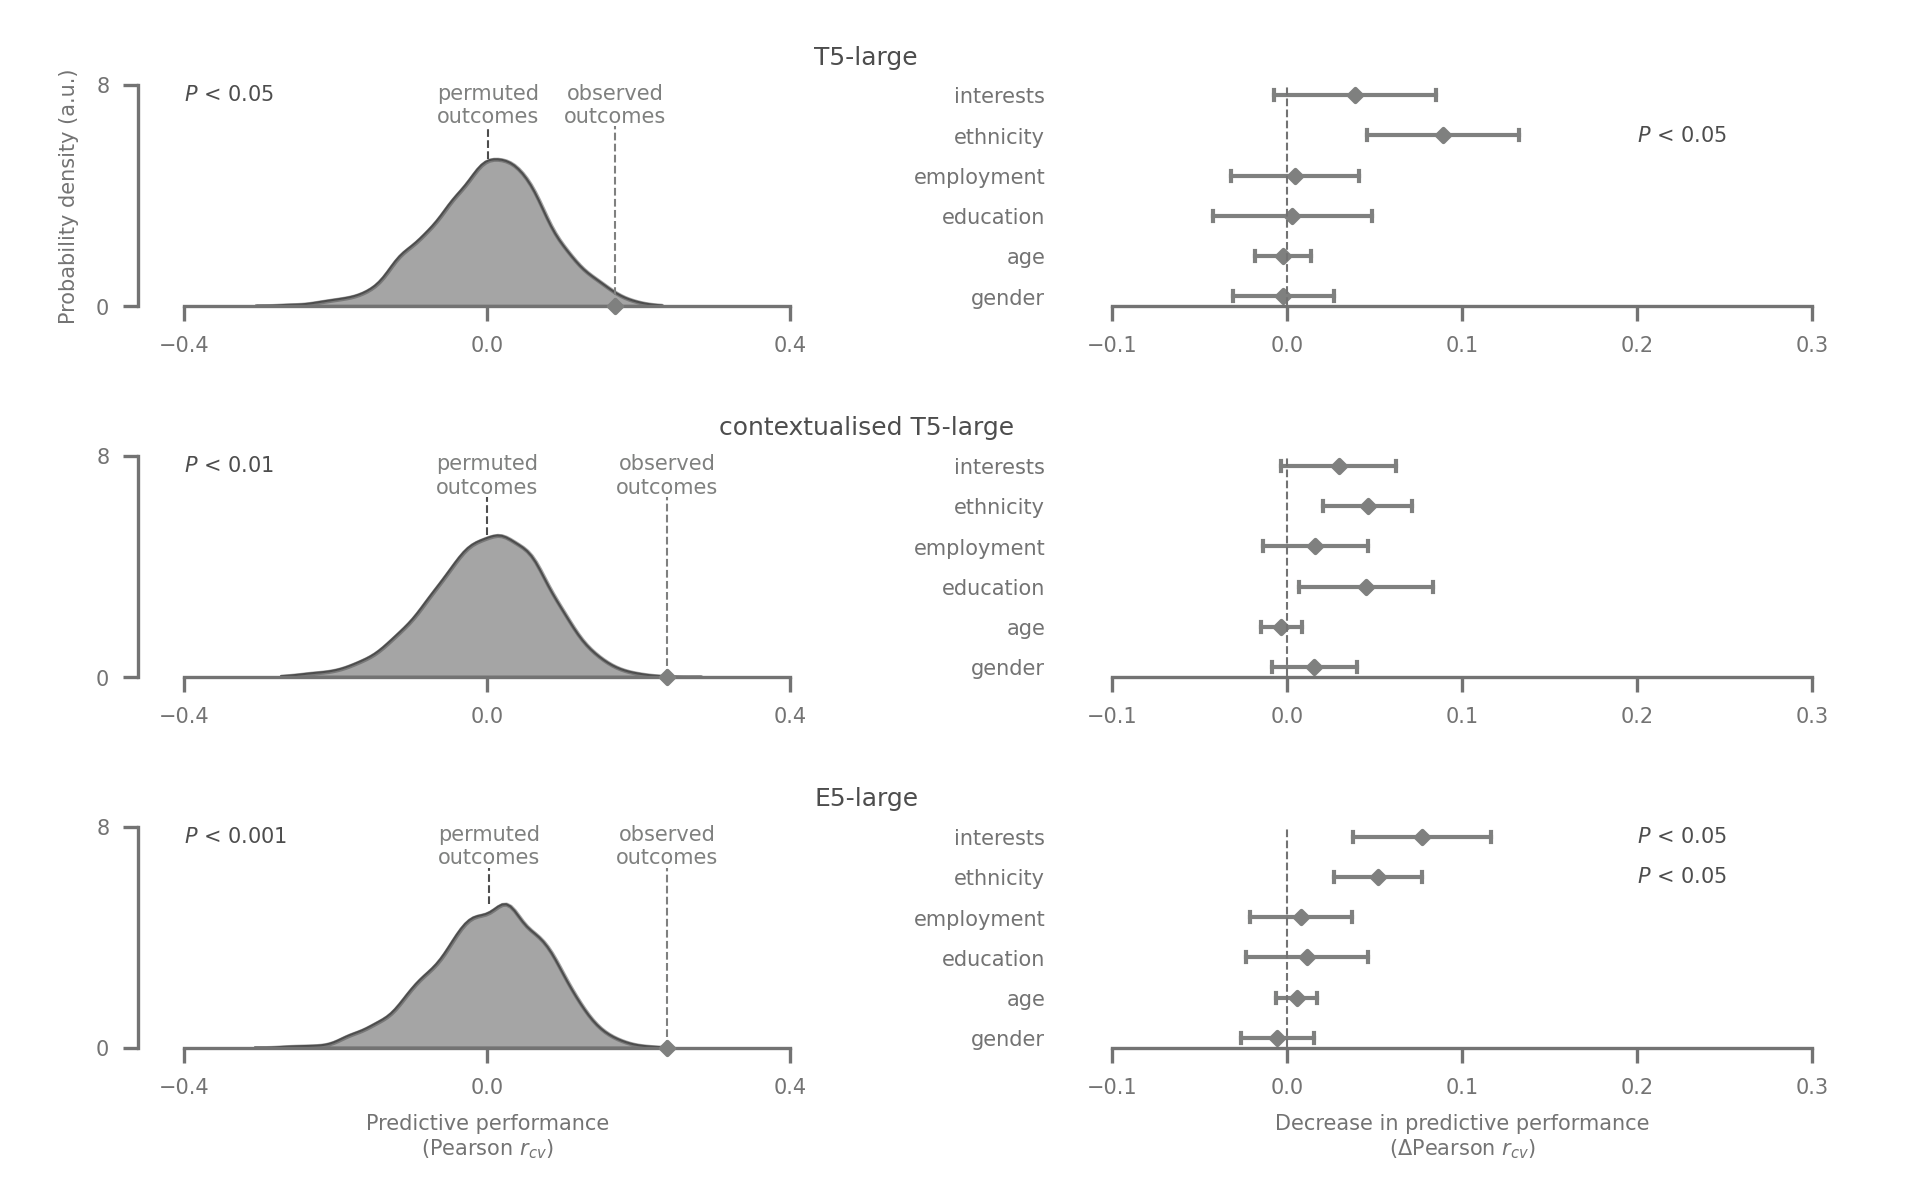

In [24]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.colors import Normalize, TwoSlopeNorm, PowerNorm, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
import matplotlib
import matplotlib.patches as mpatches

hypothesis_test = 'sign'
hypothesis_alternative = 'two-sided'
hypothesis_method = 'holm'
hypothesis_se = 'within'

run = 0
exp = 2
mod = 'glove'
modb = 'glove'
compute_stats = True

mods = [
    't5-large',
    't5-large-context',
    'e5-large'
]

mods_label = [
    fr'T5-large',
    fr'contextualised T5-large',
    fr'E5-large',
]

hypothesis_test2 = 'permutation'
hypothesis_alternative2 = 'greater'
hypothesis_method2 = 'holm'
hypothesis_se2 = 'within'

run_dem = 5
order_importance = True
order_dem = [5, 3, 4, 1, 0, 2]

rewrite_labels = {
    'gender': [
        'woman',
        'man',
        'non-binary'
    ],
    'ethnicity': [
        'asian',
        'black',
        'white'
    ],
    'education': [
        'other',
        'secondary',
        'high school',
        'college',
        'bachelor\'s',
        'master\'s',
        'doctorate'
    ],
    'employment': [
        'other',
        'job seeking',
        'newly hired',
        'part-time',
        'full-time'
    ]
}

cols = np.array([
    plots.colours.HL_EMBEDDING,
    plots.colours.HL_OTHERS,
    plots.colours.HL_SELF
])

cols2 = np.array([
    plots.colours.CM_RDM_CL(0.00),
    plots.colours.CM_RDM_CL(0.20),
    plots.colours.CM_RDM_CL(0.40)
])

'''
precompute deltas;
these are also required for ordering demographics
'''

out = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run_dem}/tasks/task-masubemb_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))

full = out['r_full'][mod][None,:].cpu().numpy()
perm = out['r_base'][mod][None,:].cpu().numpy()
block = out['r_perm'][mod].cpu().numpy().T

#desc_full = model.stats.sample_descriptives(full.T, se = hypothesis_se2)
#stat_full = model.stats.sample_tests(
#    full.mean() - perm,
#    test = hypothesis_test2, alternative = hypothesis_alternative2, 
#    method = hypothesis_method2, se = hypothesis_se2
#)

#model.stats.save_results(desc_full, './deliverable/csv/fig3/all_wthn_desc.csv')
#model.stats.save_results(stat_full, './deliverable/csv/fig3/all_wthn_block.csv')

#desc_block = model.stats.sample_descriptives((full.mean() - block).T, se = hypothesis_se2)
#stat_block = model.stats.sample_tests(
#    full.mean() - block,
#    test = hypothesis_test2, alternative = hypothesis_alternative2, 
#    method = hypothesis_method2, se = hypothesis_se2
#)

#model.stats.save_results(desc_block, './deliverable/csv/fig3/all_wthn_desc-2.csv')
#model.stats.save_results(stat_block, './deliverable/csv/fig3/all_wthn_block-2.csv')

delta = full.mean() - block
labels_D = list(out['labels'].keys())

if order_importance:
    order = delta.mean(1).argsort()
    labels_D = np.array(labels_D)[order].tolist()
else:
    order = np.arange(block.shape[0])

fig, ax = plt.subplots(figsize = (6.4, 4.0), dpi = 300)

# remove axis
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.axis('off')
    
for m_i, mod in enumerate(mods):
    out = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run_dem}/tasks/task-masubemb_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))

    full = out['r_full'][mod][None,:].cpu().numpy()
    perm = out['r_base'][mod][None,:].cpu().numpy()
    block = out['r_perm'][mod].cpu().numpy().T
    
    if compute_stats:
        desc_full = model.stats.sample_descriptives(full.T, se = hypothesis_se2)
        stat_full = model.stats.sample_tests(
            full.mean() - perm,
            test = hypothesis_test2, alternative = hypothesis_alternative2, 
            method = hypothesis_method2, se = hypothesis_se2
        )

        model.stats.save_results(desc_full, f'./deliverable/csv/suppfig5/{mod}_desc-1.csv')
        model.stats.save_results(stat_full, f'./deliverable/csv/suppfig5/{mod}_block-1.csv')

        desc_block = model.stats.sample_descriptives((full.mean() - block).T, se = hypothesis_se2)
        stat_block = model.stats.sample_tests(
            full.mean() - block,
            test = hypothesis_test2, alternative = hypothesis_alternative2, 
            method = hypothesis_method2, se = hypothesis_se2
        )

        model.stats.save_results(desc_block, f'./deliverable/csv/suppfig5/{mod}_desc-2.csv')
        model.stats.save_results(stat_block, f'./deliverable/csv/suppfig5/{mod}_block-2.csv')

    delta = full.mean() - block
    
    # full model
    ax2 = ax.inset_axes([0.0825, 0.750 - m_i * 0.335, 0.325, 0.20])

    from sklearn.neighbors import KernelDensity
    perm_pad = 0.0
    kde = KernelDensity(bandwidth = 0.015).fit(perm.T)
    x_i = np.linspace(perm.min() - perm_pad, perm.max() + perm_pad, 100)
    scores = kde.score_samples(x_i[:,None])
    scores = np.exp(scores)
    scores = scores / np.trapezoid(scores, x_i)

    min_p = stat_full[0]['p_cor']
    rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'

    ax2.plot(x_i, scores, color = plots.colours.H2, linewidth = 0.5)
    ax2.fill_between(x_i, scores, color = plots.colours.H2, alpha = 0.5)
    ax2.plot([full.mean(), full.mean()], [0.0, 6.5], color = cols[1], linewidth = 0.5, linestyle = '--')
    ax2.scatter([full.mean()], [0.0], marker = 'D', s = 5, color = cols[1], clip_on = False, zorder = 5)
    ax2.annotate('observed\noutcomes', xy = (0, 0), xytext = (full.mean(), 6.5), ha = 'center', va = 'bottom', color = cols[1], fontsize = 5)

    ax2.plot([perm.mean(), perm.mean()], [scores.max(), 6.5], color = plots.colours.H2, linewidth = 0.5, linestyle = '--')
    ax2.annotate('permuted\noutcomes', xy = (0, 0), xytext = (perm.mean(), 6.5), ha = 'center', va = 'bottom', color = cols[1], fontsize = 5)

    ax2.annotate(f'{rep_p}', xy = (0, 0), xytext = (-0.4, 8.00), ha = 'left', va = 'top', color = plots.colours.H2, fontsize = 5)

    ax2.set_xlim([-0.4, 0.4])
    ax2.set_xticks([-0.4, 0.0, 0.4])
    if m_i == 2: ax2.set_xlabel('Predictive performance\n' + fr'(Pearson $r_{{cv}}$)', fontsize = 5)
    ax2.set_ylim([0.0, 8.0])
    ax2.set_yticks([0, 8])
    if m_i == 0: ax2.set_ylabel(fr'Probability density (a.u.)', fontsize = 5)

    sns.despine(ax = ax2)
    ax2.spines['left'].set_position(('axes', -0.075))

    # individual blocks
    ax3 = ax.inset_axes([0.58, 0.750 - m_i * 0.335, 0.375, 0.20])

    order_importance = True
    bar_size = 0.125
    bar_ci = 1.96
    lw = 1.0

    min_p = 1.0

    for ii, i in enumerate(order[::-1]):
        mu = delta[i].mean()
        se = np.std(delta[i])

        ii = block.shape[0] - ii - 1
        xs, xe = ii - bar_size, ii + bar_size

        pval = stat_block[i]['p_cor']
        min_p = pval
        rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
        if pval <= 0.05:
            ax3.annotate(f'{rep_p}', xy = (0, 0), xytext = (0.2, ii), ha = 'left', va = 'center', color = plots.colours.H2, fontsize = 5)

        color = cols[1]
        bar_col = cols[1]

        ax3.plot([mu - bar_ci * se, mu + bar_ci * se], [ii, ii], color = bar_col, linewidth = lw, zorder = 1)
        ax3.plot([mu - bar_ci * se, mu - bar_ci * se], [ii - bar_size, ii + bar_size], color = bar_col, linewidth = lw, zorder = 1)
        ax3.plot([mu + bar_ci * se, mu + bar_ci * se], [ii - bar_size, ii + bar_size], color = bar_col, linewidth = lw, zorder = 1)
        ax3.scatter([mu], [ii], color = color, marker = 'D', s = 5, zorder = 2)

    ax3.plot([0, 0], [-0.5, 5.5], color = plots.colours.H3, linewidth = 0.5, linestyle = '--')

    ax3.set_ylim([-0.25, 5.25])
    ax3.set_xlim([-0.1, 0.3])
    ax3.set_yticks(np.arange(delta.shape[0]), labels = labels_D, fontsize = 5)
    ax3.set_xticks(np.arange(-0.1, 0.31, 0.1))

    if m_i == 2:
        ax3.set_xlabel('Decrease in predictive performance\n' + fr'($\Delta$Pearson $r_{{cv}}$)', fontsize = 5)

    sns.despine(ax = ax3)
    ax3.spines['left'].set_position(('axes', -0.075))
    ax3.spines['left'].set_visible(False)
    ax3.tick_params(axis = 'y', which = 'both', length = 0)

    ax3.tick_params(axis = 'both', which = 'both', labelsize = 5)
    ax3.xaxis.label.set_fontsize(5)
    ax3.yaxis.label.set_fontsize(5)

    ax2.tick_params(axis = 'both', which = 'both', labelsize = 5)
    ax2.xaxis.label.set_fontsize(5)
    ax2.yaxis.label.set_fontsize(5)
    
    for ax_i in [ax2, ax3]:
        ax_i.yaxis.label.set_color(plots.colours.H3)
        ax_i.xaxis.label.set_color(plots.colours.H3)
        ax_i.tick_params(axis = 'x', colors = plots.colours.H3)
        ax_i.tick_params(axis = 'y', colors = plots.colours.H3)
        ax_i.spines['bottom'].set_color(plots.colours.H3)
        ax_i.spines['left'].set_color(plots.colours.H3)
    
    ax2.annotate(
        mods_label[m_i],
        xy = (0, 0),
        xytext = (0.5, 9.0),
        ha = 'center',
        va = 'center',
        fontsize = 6,
        color = plots.colours.H2,
        annotation_clip = False
    )

'''
cosmetics
'''

fig.tight_layout()

ax.axis('off')

fig.savefig('./deliverable/png/suppfig5.png', dpi = 900)
fig.savefig('./deliverable/pdf/suppfig5.pdf', dpi = 900, format = 'pdf')
fig.savefig('./deliverable/svg/suppfig5.svg', dpi = 900, format = 'svg')